## 1) SUPERVISED ML - PART 1

### Linear Regression (Code)

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns

In [4]:
insurance_data = pd.read_csv("Insurance Data.csv")
insurance_data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


<Axes: xlabel='bmi', ylabel='charges'>

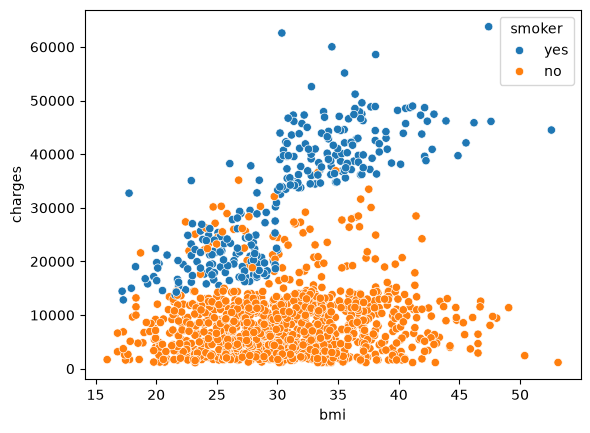

In [5]:
# Check how much company charges on basis of bmi 
sns.scatterplot(
    x = insurance_data["bmi"],
    y = insurance_data["charges"],
    hue = insurance_data["smoker"]
)
# Conclusion : BMI incraese charges increase & if Smoker then charges increase 

In [6]:
# X = insuarnce_data.drop("charges", axis = 1) # Need to mention axis for col 1 and row 0
X = insurance_data.drop(columns = ["region", "charges"]) # For rows : index = []
y = insurance_data["charges"]

In [7]:
X.head()

,age,sex,bmi,children,smoker
0,19,female,27.900,0,yes
1,18,male,33.770,1,no
2,28,male,33.000,3,no
3,33,male,22.705,0,no
4,32,male,28.880,0,no


In [8]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [9]:
# Encoding - SEX : F/M -> 1/0 & SMOKER : Y/N-> 1/0
X["sex"] = X["sex"].map({"female" : 1, "male" : 0})
X["smoker"] = X["smoker"].map({"yes" : 1, "no": 0})

# The first incorrect mapping Female and Male converted the original values into NaN, so the second mapping had nothing to match female and male cuz col was alreday overwitten with Nan.
# restarting the kernel restored the original data. So next time you write female and male but it will check Nan in that X 

In [10]:
X.head()

,age,sex,bmi,children,smoker
0,19,1,27.900,0,1
1,18,0,33.770,1,0
2,28,0,33.000,3,0
3,33,0,22.705,0,0
4,32,0,28.880,0,0


In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42)

In [12]:
X_train.head()

,age,sex,bmi,children,smoker
560,46,1,19.95,2,0
1285,47,1,24.32,0,0
1142,52,1,24.86,0,0
969,39,1,34.32,5,0
486,54,1,21.47,3,0


In [13]:
X_test.head()

,age,sex,bmi,children,smoker
764,45,1,25.175,2,0
887,36,1,30.020,0,0
890,64,1,26.885,0,1
1293,46,0,25.745,3,0
259,19,0,31.920,0,1


In [14]:
# Train Model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 257.07, 7.95, 327.53, 427.25,23653.9 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['age','sex','bmi','children','smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.212e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [15]:
# Predict Value
y_pred = model.predict(X_test)
y_pred

array([ 8554.81711589,  6973.58746745, 36798.60416104,  9417.88282303,
       26871.68031081, 11097.38383938,   145.27608963, 16746.1683771 ,
         747.53414191, 11153.67590722, 28518.15016561,  9292.18345421,
        5460.51975119, 38510.48013003, 40359.30938604, 37223.40538064,
       15316.56711945, 36047.50032223,  9326.29049907, 31400.1559532 ,
        4269.64414373, 10464.66374097,  2719.9260555 ,  6579.53742551,
       11232.00255515, 12472.06793446, 14807.11281089,  6066.19283362,
        9535.69029723,  2377.6983797 ,  9475.05690885, 12963.23366722,
        4706.09057393,  3414.674504  ,  4815.64981654, 12484.17176954,
        2359.13614479,  9161.02061228, 33238.67621442, 32743.41702445,
        4274.58967205,  4229.5442107 , 14435.36485176, 11384.66898976,
        8925.70468583, 12480.09178788,  5154.45787816,  3554.10047649,
       35649.60942684,  9276.25523701, 15971.35991397,  2552.75200479,
       12162.99980138,  1062.65132285, 13551.43771934, 12103.65505529,
      

In [16]:
y_test

764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64

### Regression Evaluation Metrices

In [18]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred) # r2_score() expects its arguments in a specific order Test -> Pred

In [19]:
X_test.shape

(268, 5)

In [20]:
n = X_test.shape[0] # Total no. of rows
p = X_test.shape[1] # Total no. of features
adjusted_r2 = 1 - ((1 - r2)*(n -1)/(n - p -1))
print("r2 score: ", r2)
print("Adjusted_r2 score: ", adjusted_r2)

r2 score:  0.7811302113434095
Adjusted_r2 score:  0.7769533069797342


### Feature Engineering - Encoding

In [23]:
# ONE HOT ENCODING
X = insurance_data.drop("charges", axis = 1) # For rows : index = []
y = insurance_data["charges"]

X["sex"] = X["sex"].map({"female" : 1, "male" : 0})
X["smoker"] = X["smoker"].map({"yes" : 1, "no": 0})


X = pd.get_dummies(X, columns = ["region"], drop_first = False)

In [24]:
X.head()

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,False,False,False,True
1,18,0,33.770,1,0,False,False,True,False
2,28,0,33.000,3,0,False,False,True,False
3,33,0,22.705,0,0,False,True,False,False
4,32,0,28.880,0,0,False,True,False,False


In [25]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42)

In [26]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [27]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred) 
print("R2_Score : ", r2)

R2_Score :  0.7835929767120723


### DUMMY VARIABLE TRAP - 

In [29]:
# drop_first = True in get_dummies()
X = insurance_data.drop("charges", axis = 1) # For rows : index = []
y = insurance_data["charges"]

X["sex"] = X["sex"].map({"female" : 1, "male" : 0})
X["smoker"] = X["smoker"].map({"yes" : 1, "no": 0})
X = pd.get_dummies(X, columns = ["region"], drop_first = True)

In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

y_pred - model.predict(X_test) #y_pred - predicted values, y_test are actual values

from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print("R2_Score : ", r2)

R2_Score :  0.7835929767120723


### Other Feature Engineering Techniques

<Axes: xlabel='age', ylabel='charges'>

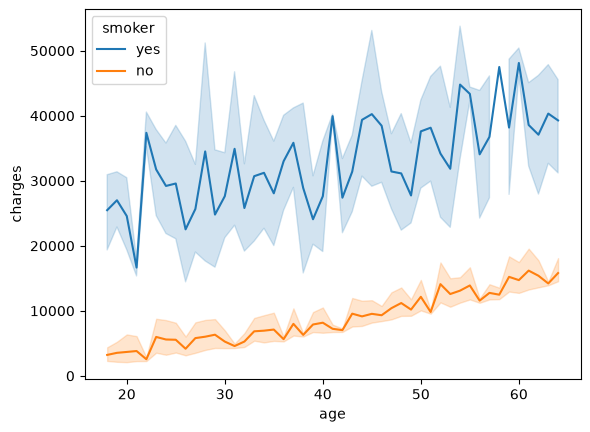

In [32]:
sns.lineplot(
   data = insurance_data,
    x = "age",
    y = "charges",
    hue = "smoker"
)
# Result - Age increase and If smoker - charges increase

In [33]:
# Pandas checks the column name in df.columns: if it already exists, it updates that column; otherwise, it creates a new column.
X = insurance_data.drop("charges", axis = 1) # For rows : index = []
y = insurance_data["charges"]

X["sex"] = X["sex"].map({"female" : 1, "male" : 0})
X["smoker"] = X["smoker"].map({"yes" : 1, "no": 0})

X = pd.get_dummies(X, columns = ["region"], drop_first = True)

X["age_smoker"] = X["age"] * X["smoker"] 
X["bmi_smoker"] = X["bmi"] * X["smoker"]
X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,age_smoker,bmi_smoker
0,19,1,27.900,0,1,False,False,True,19,27.9
1,18,0,33.770,1,0,False,True,False,0,0.0
2,28,0,33.000,3,0,False,True,False,0,0.0
3,33,0,22.705,0,0,True,False,False,0,0.0
4,32,0,28.880,0,0,True,False,False,0,0.0


In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test) #y_pred - predicted values, y_test are actual values

from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print("R2_Score : ", r2)

R2_Score :  0.865231697953168


### Is model Overfit or Underfit?

In [74]:
# R2_score - training low & testing low - Underfit
# R2_score - tarining High & testing Low - Overfit

y_pred_train = model.predict(X_train)
r2_train = r2_score(y_train, y_pred_train)

# Normal r2 is always of testing 

print("Training R2 Score : ", r2_train)
print("Testing R2 Score : ", r2)

# Result -> Good Model Performance -> no overfit /underfit

Training R2 Score :  0.8340713711218875
Testing R2 Score :  0.865231697953168


In [76]:
insurance_data.shape

(1338, 7)